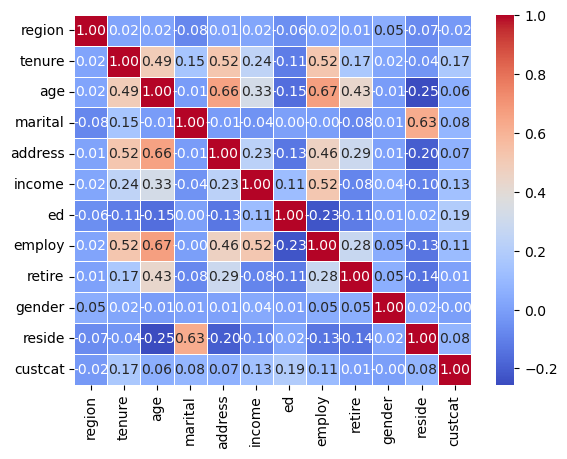

Accuracy score:  0.315
Inference Time: 0.002207040786743164


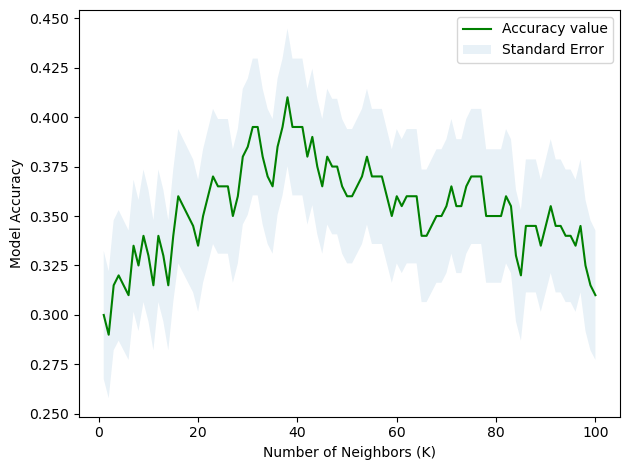

0.41 is the best accuracy score with k=  38


In [34]:
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score 
import time

df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/teleCust1000t.csv')
df.head()

df['custcat'].value_counts() #To see each service calss has how many users, pretty balanced 

correlation_matrix=df.corr() 
plt.Figure(figsize=(10,6)) 
sns.heatmap(correlation_matrix,annot=True,fmt='.2f',cmap='coolwarm',linewidths=0.5) #how different features are related to each other
#The more we go towards red the more related the two features (Same features give you the highest relation obviously) 

correlation_values=abs(df.corr()['custcat'].drop('custcat')).sort_values(ascending=False)# we are interested in the relations between each feature and the target variable
correlation_values # Sorting the correlation values in a descending order, ed and tenure are the most important features; retire and gender are the least important features 
plt.show()   # show it, and finish that figure

# --- second plot: accuracy vs K, with error band ---
plt.figure()  
X=df.drop('custcat',axis=1)
y=df['custcat'] 

X_norm=StandardScaler().fit_transform(X) #Scaling bcuz KNN is based on distance I don't want the model to favor anything bcuz of magnitude. This will put all feature on a same scale 
X_train, X_test, y_train, y_test = train_test_split(X_norm, y, test_size=0.2, random_state=4) 

k=3
knn_classifier=KNeighborsClassifier(n_neighbors=k) 
knn_model=knn_classifier.fit(X_train,y_train)
start=time.time()
y_hat=knn_model.predict(X_test) 
end=time.time()
print("Accuracy score: ",accuracy_score(y_test,y_hat))

print("Inference Time:",end-start)

ks=100
acc=np.zeros((ks)) #makes an empty list of 10 zeros to store the accuracy for each k, e.g. acc[0] will be for k=1, acc[9] for k=10
std_acc=np.zeros((ks)) #to store the error bar (standard error) of the accuracy for each K
for n in range(1,ks+1):
    knn_model_n=KNeighborsClassifier(n_neighbors=n).fit(X_train,y_train)
    knnn_yhat=knn_model_n.predict(X_test)
    acc[n-1]=accuracy_score(y_test,knnn_yhat) 
    std_acc[n-1]=np.std(knnn_yhat==y_test)/np.sqrt(knnn_yhat.shape[0]) #yhat = np.array([0, 1, 0, 1, 1]) for example (5,1) then divide by root5

plt.plot(range(1,ks+1),acc,'g')
plt.fill_between(range(1, ks+1), acc - 1 * std_acc, acc + 1 * std_acc, alpha=0.10)
plt.legend(('Accuracy value', 'Standard Error'))
plt.ylabel('Model Accuracy')
plt.xlabel('Number of Neighbors (K)')
plt.tight_layout()
plt.show()

print(acc.max(), "is the best accuracy score with k= ",acc.argmax()+1)
#Acc score with k=30 0.385 , k=9 0.34, k=38 0.41 therefore the k=38 is the most optimal k 
